# 09 Gradient boosting: regularisation and seed sensitivity

Notebooks 07 and 08 used one fixed setting (300 trees, 15 leaves). Feature set A (calendar + history) was worse than the baseline, which suggests the model fits noise. Here a small grid fixed in advance varies model complexity, on direct price, absolute-error loss, expanding window, 09:00 cutoff, same 17 folds. The whole grid is reported; the point is how stable the gain over the baseline is across settings, not to pick the best cell (picking the best of 36 on these folds would overstate its performance).

## Init

In [1]:
import sys, time, itertools
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor

from _eval import make_folds, score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

T = pd.read_parquet("outputs/feature_table_dev.parquet")
D9 = T[T["cutoff_hour"] == 9].reset_index(drop=True)
days = pd.DatetimeIndex(sorted(D9["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
VAL = D9["day"].isin(val_days_all)
print("scikit-learn", sklearn.__version__, "|", int(VAL.sum()), "validation rows,", len(folds), "folds")

CAL = ["hour_frac", "weekday", "is_weekend", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"]
HIST = ["d2_same", "med7_same", "med28_same", "level7", "level28", "level24h", "level_gap"]
FC = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw", "wind_total_mw",
      "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"]
MG = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
CORE = ["hour_frac", "weekday", "is_weekend", "bank_holiday", "med7_same", "med28_same",
        "demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]          # the features that carried importance in 07/08
SETS = {"A": CAL + HIST, "R (core)": CORE, "C": CAL + HIST + FC + MG}
for k, v in SETS.items():
    print(k, len(v), "features")

scikit-learn 1.9.1 | 22847 validation rows, 17 folds
A 14 features
R (core) 10 features
C 31 features


## 1. Grid

Fixed in advance: leaves {4, 8, 15} x minimum rows per leaf {100, 400} x (trees, learning rate) {(100, 0.05), (300, 0.05)} = 12 settings, on three feature sets (A, a reduced core set R, and the full set C) = 36 configurations. The 07 setting (15 leaves, 100 rows, 300 trees) is one cell of the grid. Smaller leaves, bigger minimum leaf size and fewer trees all mean a simpler model.

In [2]:
def run_cv(cols, leaves, min_leaf, iters, lr, seed=0, max_features=1.0):
    pred = pd.Series(np.nan, index=D9.index)
    for f in folds:
        tr = D9[D9["day"].isin(f["train_days"]) & D9["price"].notna()]
        va = D9[D9["day"].isin(f["val_days"])]
        m = HistGradientBoostingRegressor(loss="absolute_error", max_leaf_nodes=leaves, min_samples_leaf=min_leaf,
                                          max_iter=iters, learning_rate=lr, l2_regularization=1.0,
                                          early_stopping=False, max_features=max_features, random_state=seed)
        m.fit(tr[cols], tr["price"])
        pred.loc[va.index] = m.predict(va[cols])
    return pred

def fold_table(pred):
    rows = []
    for f in folds:
        d = D9[D9["day"].isin(f["val_days"])].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")

BASE = fold_table(D9["med28_same"])
GRID = list(itertools.product([4, 8, 15], [100, 400], [(100, 0.05), (300, 0.05)]))
RES, PRED = [], {}
t0 = time.time()
for sname, cols in SETS.items():
    for leaves, min_leaf, (iters, lr) in GRID:
        p = run_cv(cols, leaves, min_leaf, iters, lr)
        ft = fold_table(p)
        d = {m: ft[m] - BASE[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]}
        RES.append({"set": sname, "leaves": leaves, "min_leaf": min_leaf, "trees": iters,
                    "MAE": ft["MAE"].mean(), "bias": ft["bias"].mean(),
                    "dMAE": d["MAE"].mean(), "dMAE_se": d["MAE"].std() / np.sqrt(17), "folds_MAE_better": int((d["MAE"] < 0).sum()),
                    "dRMSE": d["RMSE"].mean(),
                    "dHitTop": d["hit_top8"].mean(), "dHitTop_se": d["hit_top8"].std() / np.sqrt(17),
                    "dHitBot": d["hit_bot8"].mean(), "dHitBot_se": d["hit_bot8"].std() / np.sqrt(17)})
        PRED[(sname, leaves, min_leaf, iters)] = p
print(f"{len(RES)} configurations in {time.time() - t0:.0f}s")
G = pd.DataFrame(RES)
print("baseline mean-per-fold MAE:", round(BASE["MAE"].mean(), 2))

36 configurations in 243s
baseline mean-per-fold MAE: 30.2


## 2. Full grid

Columns: mean of per-fold MAE; `dMAE` = difference to the baseline (negative is better) with standard error across folds; the number of folds (of 17) in which MAE is better than the baseline; differences in top-8 and bottom-8 hit rate.

In [3]:
show = G.copy()
show["dMAE"] = show.apply(lambda r: f"{r.dMAE:+.2f} +/- {r.dMAE_se:.2f}", axis=1)
show["dHitTop"] = show.apply(lambda r: f"{r.dHitTop:+.3f} +/- {r.dHitTop_se:.3f}", axis=1)
show["dHitBot"] = show.apply(lambda r: f"{r.dHitBot:+.3f} +/- {r.dHitBot_se:.3f}", axis=1)
print(show[["set", "leaves", "min_leaf", "trees", "MAE", "bias", "dMAE", "folds_MAE_better", "dRMSE", "dHitTop", "dHitBot"]].round(2).to_string(index=False))

     set  leaves  min_leaf  trees   MAE  bias           dMAE  folds_MAE_better  dRMSE          dHitTop          dHitBot
       A       4       100    100 30.22  0.92 +0.02 +/- 0.22                 8  -0.53 +0.002 +/- 0.004 -0.043 +/- 0.016
       A       4       100    300 31.14 -0.83 +0.93 +/- 0.48                 6   0.29 +0.004 +/- 0.005 -0.024 +/- 0.015
       A       4       400    100 30.20  0.88 -0.00 +/- 0.23                 8  -0.55 +0.001 +/- 0.005 -0.040 +/- 0.015
       A       4       400    300 31.24 -0.22 +1.04 +/- 0.46                 6   0.49 +0.005 +/- 0.005 -0.027 +/- 0.014
       A       8       100    100 30.94 -0.24 +0.74 +/- 0.36                 5   0.09 +0.001 +/- 0.004 -0.022 +/- 0.013
       A       8       100    300 32.16 -1.75 +1.95 +/- 0.59                 3   1.26 +0.003 +/- 0.004 -0.005 +/- 0.010
       A       8       400    100 30.62  0.30 +0.42 +/- 0.31                 6  -0.29 +0.001 +/- 0.004 -0.017 +/- 0.015
       A       8       400    300 32.10 

## 3. Summary by feature set

Range and median of the MAE difference to the baseline across the 12 settings of each feature set, and how many settings beat the baseline.

In [4]:
S = G.groupby("set").agg(settings=("dMAE", "size"), dMAE_min=("dMAE", "min"), dMAE_median=("dMAE", "median"), dMAE_max=("dMAE", "max"),
                         beat_baseline=("dMAE", lambda s: int((s < 0).sum())),
                         dHitTop_median=("dHitTop", "median"), dHitBot_median=("dHitBot", "median"),
                         bias_median=("bias", "median")).round(3)
print(S.to_string())

          settings  dMAE_min  dMAE_median  dMAE_max  beat_baseline  dHitTop_median  dHitBot_median  bias_median
set                                                                                                            
A               12    -0.005        1.066     2.593              1           0.002          -0.015       -0.537
C               12    -1.894       -1.799    -1.716             12           0.029           0.046       -3.967
R (core)        12    -2.351       -2.170    -2.091             12           0.025           0.042       -5.728


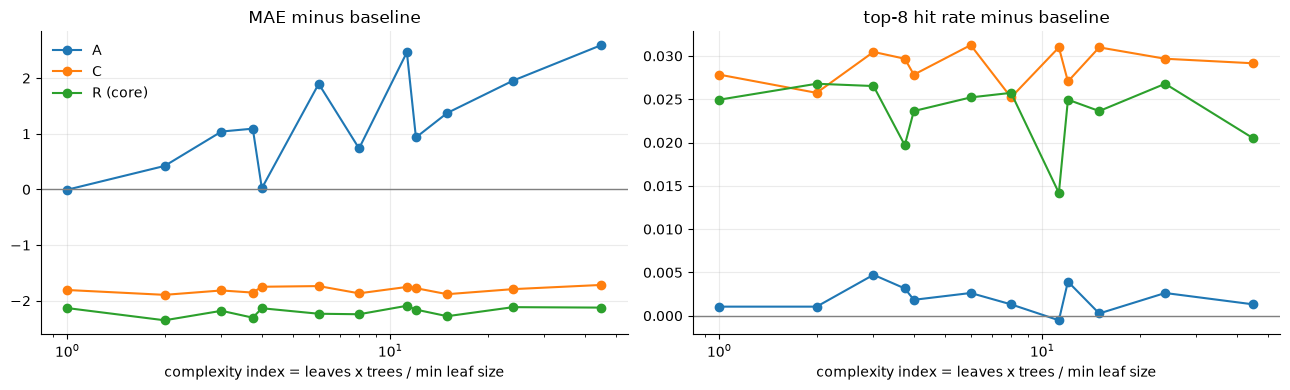

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
G["complexity"] = G["leaves"] * G["trees"] / G["min_leaf"]
for s, g in G.groupby("set"):
    g = g.sort_values("complexity")
    axes[0].plot(g["complexity"], g["dMAE"], marker="o", label=s)
    axes[1].plot(g["complexity"], g["dHitTop"], marker="o", label=s)
for ax, t in zip(axes, ["MAE minus baseline", "top-8 hit rate minus baseline"]):
    ax.axhline(0, color="grey", lw=1); ax.set_xscale("log"); ax.set_title(t)
    ax.set_xlabel("complexity index = leaves x trees / min leaf size")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. Seed sensitivity

With all features and no column subsampling the algorithm is deterministic, so the seed changes nothing. To see whether run-to-run randomness matters, repeat the 07 setting with a random 70% of the features considered at each split and five seeds (a different model, used only to measure that variation).

In [6]:
seeds = {}
for sd in range(5):
    p = run_cv(SETS["C"], 15, 100, 300, 0.05, seed=sd, max_features=0.7)
    ft = fold_table(p)
    seeds[sd] = {"MAE": ft["MAE"].mean(), "dMAE": (ft["MAE"] - BASE["MAE"]).mean(), "dHitTop": (ft["hit_top8"] - BASE["hit_top8"]).mean(),
                 "dHitBot": (ft["hit_bot8"] - BASE["hit_bot8"]).mean()}
SD = pd.DataFrame(seeds).T
print(SD.round(3).to_string())
print("std across seeds:", SD.std().round(3).to_dict())

      MAE   dMAE  dHitTop  dHitBot
0  28.596 -1.607    0.029    0.041
1  28.328 -1.875    0.026    0.043
2  28.313 -1.890    0.030    0.038
3  28.294 -1.909    0.027    0.037
4  28.478 -1.724    0.028    0.037
std across seeds: {'MAE': 0.131, 'dMAE': 0.131, 'dHitTop': 0.002, 'dHitBot': 0.003}


## 5. Does the reduced set lose anything?

Paired comparison, fold by fold, of the reduced set R against the full set C, at the same four settings: the 07 setting and the most regularised one.

In [7]:
def paired_vs(a, b):
    fa, fb = fold_table(PRED[a]), fold_table(PRED[b])
    out = {}
    for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
        d = fa[m] - fb[m]
        out[m] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"
    return out
rows = {}
for leaves, min_leaf, iters in [(15, 100, 300), (4, 400, 100), (8, 400, 100), (4, 100, 300)]:
    rows[f"R vs C, {leaves} leaves, min leaf {min_leaf}, {iters} trees"] = paired_vs(("R (core)", leaves, min_leaf, iters), ("C", leaves, min_leaf, iters))
print(pd.DataFrame(rows).T.to_string())

                                                         MAE              RMSE          hit_top8          hit_bot8
R vs C, 15 leaves, min leaf 100, 300 trees  -0.407 +/- 0.395  -0.157 +/- 0.426  -0.009 +/- 0.007  -0.017 +/- 0.011
R vs C, 4 leaves, min leaf 400, 100 trees   -0.325 +/- 0.138  -0.281 +/- 0.187  -0.003 +/- 0.003  +0.003 +/- 0.003
R vs C, 8 leaves, min leaf 400, 100 trees   -0.457 +/- 0.263  -0.403 +/- 0.313  +0.001 +/- 0.003  +0.008 +/- 0.004
R vs C, 4 leaves, min leaf 100, 300 trees   -0.385 +/- 0.271  -0.279 +/- 0.348  -0.002 +/- 0.004  -0.000 +/- 0.006


## Findings (direct price, absolute loss, expanding window, 09:00 cutoff; 36 configurations)

- **The gain over the baseline is stable across settings.** For the full set C, all 12 settings beat the 28-day median: MAE difference -1.7 to -1.9 (standard errors about 0.73-0.84), RMSE -3.5 to -3.8, top-8 hit +0.025 to +0.031, bottom-8 +0.034 to +0.050. The 07 result was not a lucky setting. Complexity matters little: simpler trees (4 leaves) do as well as 15 leaves, and 300 trees are no better than 100.
- **Set A was overfitting.** With the same grid, A is worse than the baseline for 11 of 12 settings, and the median difference is +1.1. Only the two simplest settings (4 leaves, 100 trees) reach the baseline (MAE -0.00 to +0.02) and none beats it, so history features alone have nothing to add over the profile. This confirms the diagnosis from 08.
- **The reduced set R (10 features) beats C in every setting:** MAE -2.1 to -2.35 against the baseline versus -1.7 to -1.9 for C; RMSE -3.7 to -4.2. Directly, R minus C is about -0.33 to -0.46 MAE (std errors 0.14-0.40); hit rates are not different (within about 0.02). **Caveat: I chose R's features by looking at permutation importance on folds 8 and 16 in notebooks 07/08, which are validation folds. R's edge over C is therefore optimistic.** The C results are not affected by this. A fair test would select features using only data before each fold; I have not done it.
- **Seed variation is negligible.** With 70% feature subsampling, five seeds give MAE differences to the baseline of -1.61 to -1.91 (std 0.13) and hit-rate differences varying by 0.002-0.003, about 6 times smaller than the fold-to-fold standard error. Without subsampling the model is deterministic.
- **Bias.** All weather-feature models have negative bias (-3.6 to -6.4), the more so for R and the more trees. Set A is closer to zero (-2.6 to +0.9). I still have not checked what share of actual prices lie above the forecast, so I cannot say whether this is skew (mean above median) or a genuine under-forecast; that is the first thing to look at before trusting level accuracy.
- **Overall.** The improvement is about 2 MAE (6-7% of 30), 3.5-4 RMSE, and about +0.03/+0.045 hit rate (around 0.2 and 0.35 more correct periods out of 8 per day). It is robust to model complexity and seed, and is concentrated in demand, wind and solar forecasts. It is a modest gain, and does not yet address high-price tails.
